*  DSC530-T301 Data Exploration and Analysis (2263-1)
*  Weeks 7 & 8 Coding Assignment
*  David Jorgensen

# Pandas, Matplotlib, and Seaborn

In [ ]:
# Prep Libraries and Data
# Libraries
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Data
earthquake_data = pd.read_csv('./textbook/ch_05/data/earthquakes.csv')
facebook_data = pd.read_csv('./textbook/ch_05/data/fb_stock_prices_2018.csv')

# Chapter 5, Exercise 1

Plot the rolling 20-day minimum of the Facebook closing price using pandas.

<Axes: title={'center': 'Rolling Minimum of Facebook Closing Price (20-day window)'}, xlabel='date', ylabel='Rolling Minimum Price'>

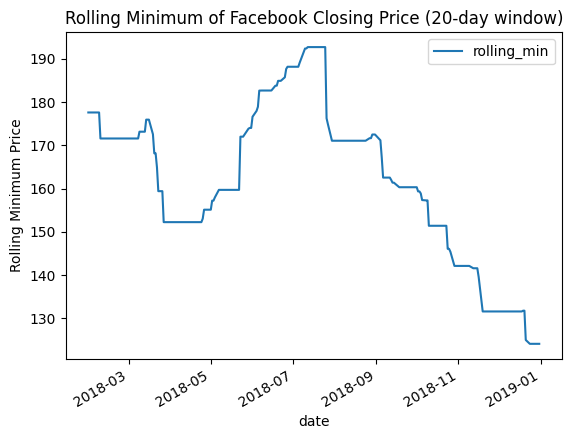

In [30]:
# Format date columns
facebook_data['date'] = pd.to_datetime(facebook_data['date'])
facebook_data = facebook_data.sort_values('date')
# Calculate rolling minimum of Facebook closing price with a window of 20 days
facebook_data['rolling_min'] = facebook_data['close'].rolling(window=20).min()
# Plot the rolling minimum of Facebook closing price over time
facebook_data.plot(x='date', y='rolling_min', title='Rolling Minimum of Facebook Closing Price (20-day window)', ylabel='Rolling Minimum Price')

## Chapter 5, Exercise 2

Create a histogram and KDE of the change from open to close in the price of Facebook stock.

<Axes: title={'center': 'Histogram of Price Change from Open to Close in Facebook Stock'}, ylabel='Frequency'>

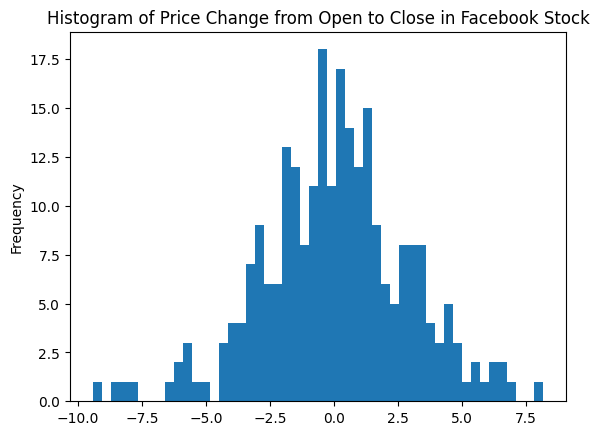

In [31]:
# Calculate the change from open to close in the price of Facebook stock
facebook_data['price_change'] = facebook_data['close'] - facebook_data['open']
# Plot histogram
facebook_data['price_change'].plot(kind='hist', bins=50, title='Histogram of Price Change from Open to Close in Facebook Stock')

<Axes: title={'center': 'KDE of Price Change from Open to Close in Facebook Stock'}, ylabel='Density'>

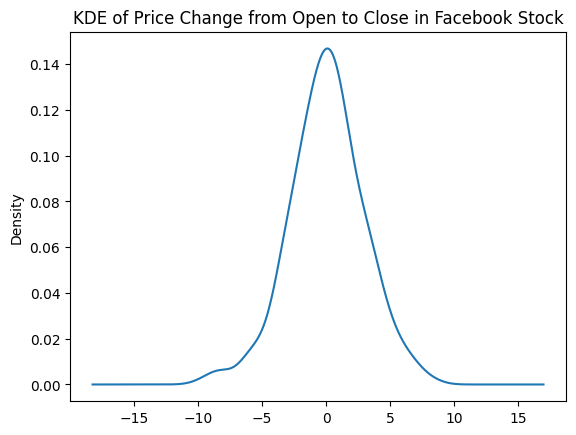

In [32]:
# Plot KDE
facebook_data['price_change'].plot(kind='kde', title='KDE of Price Change from Open to Close in Facebook Stock')

## Chapter 5, Exercise 3

Using the earthquake data, create box plots for the magnitudes of each magType used in Indonesia.

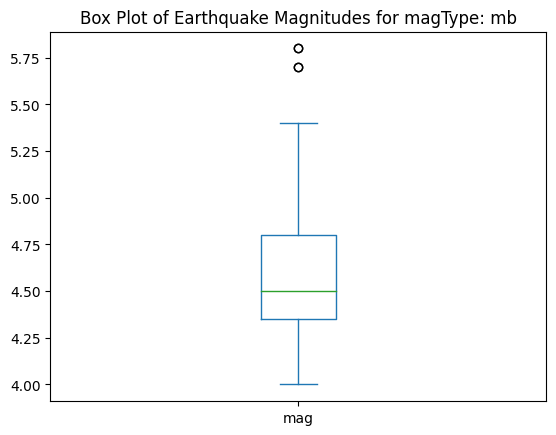

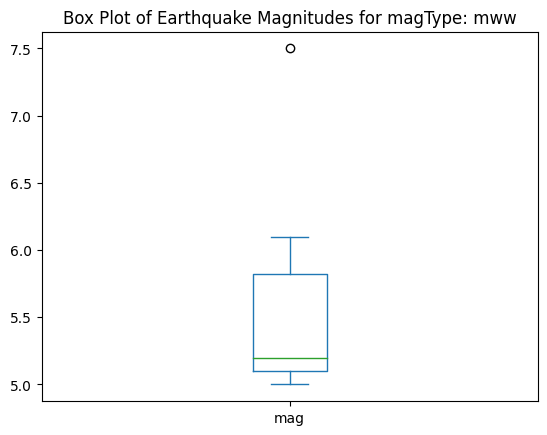

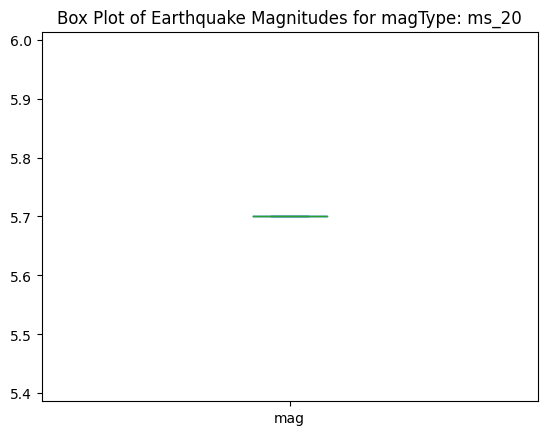

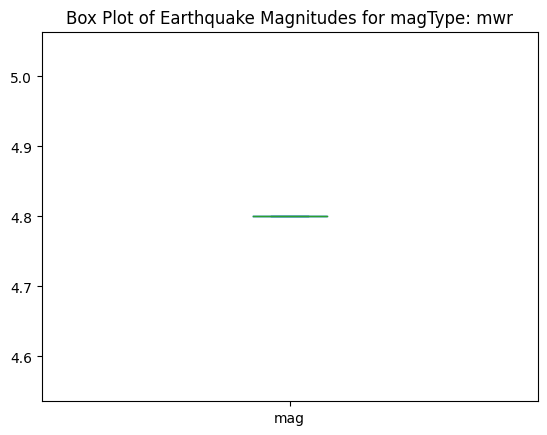

In [33]:
# Filter down to Indonesia
earthquake_data_indonesia = earthquake_data[earthquake_data['parsed_place'].str.lower() == 'indonesia']
# Create a box plot of the magnitudes of earthquakes in Indonesia, grouped by magnitude type (magType)
for magType in earthquake_data_indonesia['magType'].unique():
    mag_data = earthquake_data_indonesia[earthquake_data_indonesia['magType'] == magType]
    mag_data.plot(y='mag', kind='box', title=f'Box Plot of Earthquake Magnitudes for magType: {magType}')

## Chapter 5, Exercise 4

Make a line plot of the difference between the weekly maximum high price and the weekly minimum low price for Facebook. This should be a single line.

<Axes: title={'center': 'Weekly Price Range for Facebook Stock'}, xlabel='date', ylabel='Price Range'>

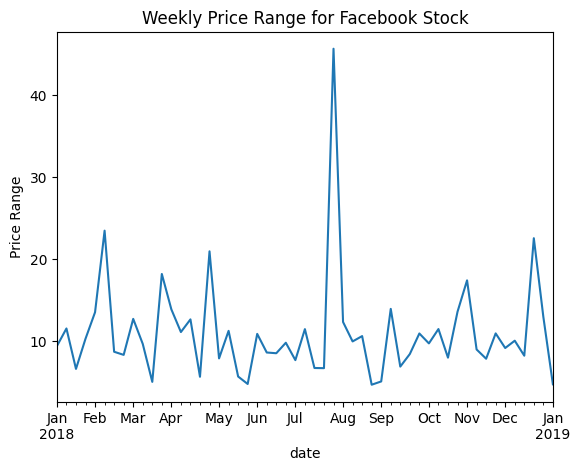

In [34]:
# Calculate the weekly price range for Facebook stock
facebook_weekly = facebook_data.set_index('date').resample('W').agg({'high': 'max', 'low': 'min'})
facebook_weekly['weekly_price_range'] = facebook_weekly['high'] - facebook_weekly['low']
# Plot the weekly price range using pandas
facebook_weekly['weekly_price_range'].plot(title='Weekly Price Range for Facebook Stock', ylabel='Price Range')

## Chapter 6, Exercise 1

Using Seaborn, create a heatmap to visualize the correlation coefficients between earthquake magnitude and whether there was a tsunami for earthquakes measured with the mb magnitude type.

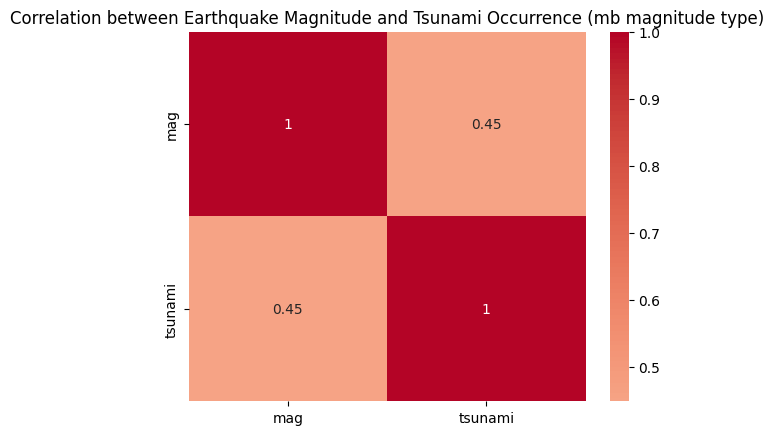

In [35]:
# Filter down to mb magnitude type
mb_earthquakes = earthquake_data[earthquake_data['magType'] == 'mb']
# Calculate correlation matrix
correlation_matrix = mb_earthquakes[['mag', 'tsunami']].corr()
# Create heatmap
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0)
plt.title('Correlation between Earthquake Magnitude and Tsunami Occurrence (mb magnitude type)')
plt.show()

## Chapter 6, Exercise 2

Create a box plot of Facebook volume traded and closing prices and draw reference lines for the bounds of a Tukey fence with a multiplier of 1.5. The bounds will be at Q1 − 1.5 × IQR and Q3 + 1.5 × IQR. Be sure to use the quantile() method on the data to make this easier. Pick whichever orientation you prefer for the plot, but make sure to use subplots.

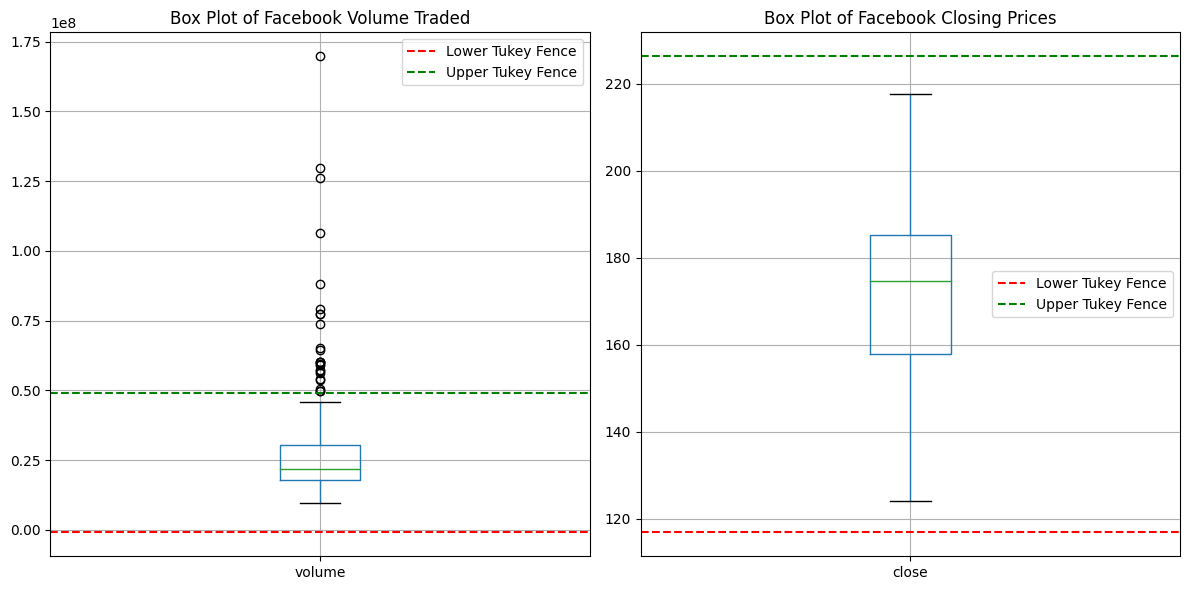

In [36]:
# Define subplots
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
# Box plot for volume traded
facebook_data.boxplot(column='volume', ax=axes[0])
axes[0].set_title('Box Plot of Facebook Volume Traded')
# Calculate Tukey fence bounds for volume
Q1_volume = facebook_data['volume'].quantile(0.25)
Q3_volume = facebook_data['volume'].quantile(0.75)
IQR_volume = Q3_volume - Q1_volume
lower_bound_volume = Q1_volume - 1.5 * IQR_volume
upper_bound_volume = Q3_volume + 1.5 * IQR_volume
# Add reference lines for Tukey fence bounds
axes[0].axhline(lower_bound_volume, color='red', linestyle='--', label='Lower Tukey Fence')
axes[0].axhline(upper_bound_volume, color='green', linestyle='--', label='Upper Tukey Fence')
axes[0].legend()
# Box plot for closing prices
facebook_data.boxplot(column='close', ax=axes[1])
axes[1].set_title('Box Plot of Facebook Closing Prices')
# Calculate Tukey fence bounds for closing prices
Q1_close = facebook_data['close'].quantile(0.25)
Q3_close = facebook_data['close'].quantile(0.75)
IQR_close = Q3_close - Q1_close
lower_bound_close = Q1_close - 1.5 * IQR_close
upper_bound_close = Q3_close + 1.5 * IQR_close
# Add reference lines for Tukey fence bounds
axes[1].axhline(lower_bound_close, color='red', linestyle='--', label='Lower Tukey Fence')
axes[1].axhline(upper_bound_close, color='green', linestyle='--', label='Upper Tukey Fence')
axes[1].legend()
plt.tight_layout()
plt.show()